In [1]:

##############################################################
###  This Notebook can do interact, see instructions below ###
##############################################################


# -*- coding: utf-8 -*-
"""
Created on Mon Jun 30 22:06:32 2025

@author: jiaxx213
"""

import torch
import torch.nn as nn
import torch.optim as optim
import pickle
import os
import sys
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split, Subset

from functions_basic import var_list, load_sourcedata, exist_split, create_split, random_new_seed, get_all_seeds
from functions_data import Data_Manager
from functions_LITT import Trainer_LITT
from functions_Events import Event_Analyzer
from functions_Path import Path_Analyzer

#method_name = "T2" # 
split_rate = 0.7
hidden_size = 16

n_batch = 32
n_epochs = 35
n_epoches_gamma = 35

#-------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("GPU is available!")
    print(torch.cuda.get_device_name(0))
else:
    print("Warning! No GPU available, back to CPU")

var_dict = {s: i for i, s in enumerate(var_list)}
dim_x = len(var_list)

#-------------------
loaded_data = load_sourcedata()
sequences = loaded_data['sequences']
time_sequences = loaded_data['time_sequences']
targets_dict = loaded_data['targets']
last_days = loaded_data['last_days']
pid_list = loaded_data['pid_list']

#'HF','IS','ARR','CA'
oc_names = ['HF','IS','ARR','AM','CA']

oc_targets = {k: targets_dict[k] for k in oc_names}
last_days = torch.tensor(last_days, dtype=torch.float32)

# ---------------------
data_manager = Data_Manager(sequences, time_sequences, oc_targets, hidden_size, n_batch, device)
data_manager.load_full()

#trainer_LITT = Trainer_LITT(data_manager)
#trainer_LITT.loading()
#dataloader_LITT, _ = data_manager.get_DataLoader('LITT')
#trainer_LITT.run_training(n_epochs, dataloader_LITT)
#trainer_LITT.run_flipping(n_epochs, data_manager)

#event_analyzer = Event_Analyzer(data_manager, pid_list)
#event_analyzer.load_events()
#recur_dict = event_analyzer.do_analyze(log_out=False)

# slt_evts = ['metformin_1', 'insulin_1', 'sulfonylurea_1', 'glp1_recpt_1', 'sglt2_inhib_1', 'glp1_recpt_1', 'ezetimibe_1', 'fibrates_1', 'bile_acid_1', 'diuretics_1', 'diabetes_1', 'hypertension_1', 'obesity_1', 'smoking_1', 'ckd_1']
# event_analyzer.disp_3heatmap([("radiation",1)], [("anthracyclins",1)], [("targeted",1)], slt_evts)


#path_analyzer = Path_Analyzer(data_manager, pid_list)
#path_analyzer.loading()

#path_list = path_analyzer.select_path(recur_dict)
#path_analyzer.compact_path(path_list)


event_path_fname = './BC_LITT/full_LITT_event_paths'
with open(event_path_fname, 'rb') as f:
    recur_dict = pickle.load(f)


path_analyzer = Path_Analyzer(data_manager)
path_analyzer.loading()
slt_keys = ['anthracyclins', 'targeted', 'radiation', 'diabetes', 'hypertension', 'obesity', 'ckd', 'metformin', 'insulin', 'sulfonylurea', 'glp1_recpt', 'sglt2_inhib', 'ezetimibe', 'fibrates', 'bile_acid', 'diuretics']

path_list = path_analyzer.select_path(recur_dict, slt_keys, 6)
#print(f"n_paths = {len(path_list)}")


from functions_Flipped import Flipping_Analyzer


flip_analyzer = Flipping_Analyzer(data_manager, recur_dict, path_list)
flip_analyzer.loading()
flip_analyzer.do_analysis()



GPU is available!
NVIDIA A100 80GB PCIe
Data Manager: full training loaded.
Data Manager: 835 / 3276 label flipped.
Loading existing timing from ./BC_LITT/full_LITT_flip_timing.pkl ...
Loading full_timing from ./BC_LITT/full_LITT_timing.pkl ...
Loading existing flipped_timing from ./BC_LITT/full_LITT_flipped_timing.pkl ...


In [2]:
recur_dict.keys()

dict_keys(['Radia_2', 'Radia_3', 'Chemo_3', 'Targt_3', 'Radia_1', 'Chemo_2', 'Targt_1', 'Chemo_1', 'Targt_2', 'Dx_DB_2', 'Dx_DB_3', 'Dx_HT_3', 'DxSmk_1', 'Dx_DB_1', 'M_Mtf_1', 'Dx_HT_2', 'Dx_HT_1', 'Dx_Ob_1', 'Dx_HL_1', 'M_Diu_1', 'DxCKD_3', 'DxCKD_1', 'DxCKD_2', 'Dx_HL_2', 'Dx_HL_3', 'Dx_Ob_2', 'Dx_Ob_3', 'DxSmk_2', 'M_Sul_1', 'DxSmk_3', 'M_Ezt_1', 'M_Ins_1', 'M_GLP_1'])

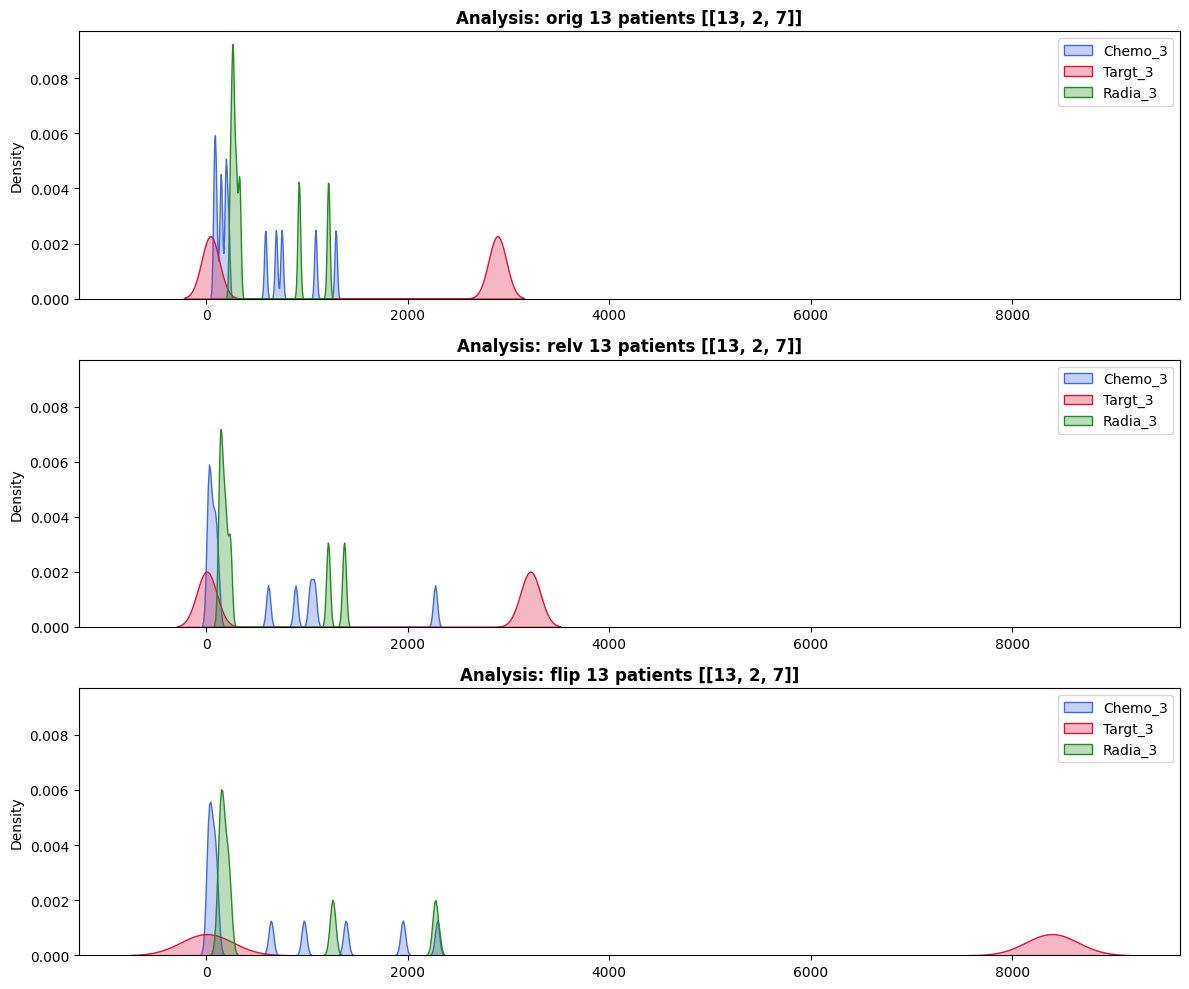

In [22]:
#idxs = flip_analyzer.get_body_idxs(pre_events)
#len(idxs)
path_id = 54
path_step = -1   # -1 for full path
path_info = [path_id, path_step]
plt_events = ['Chemo_3', 'Targt_3', 'Radia_3']
flip_analyzer.plot_compare(path_info, plt_events, 0.05)

positive 13, negative 8


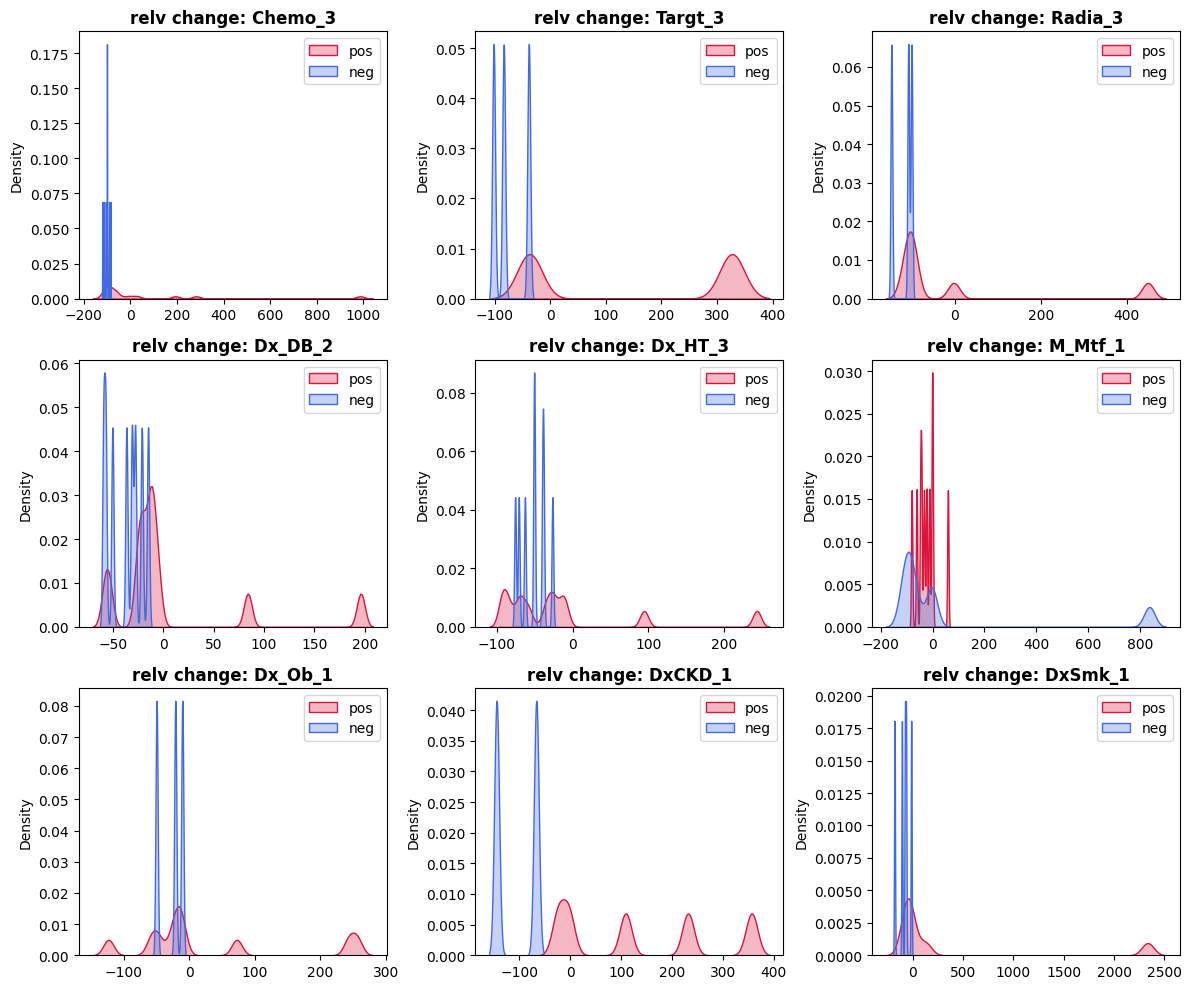

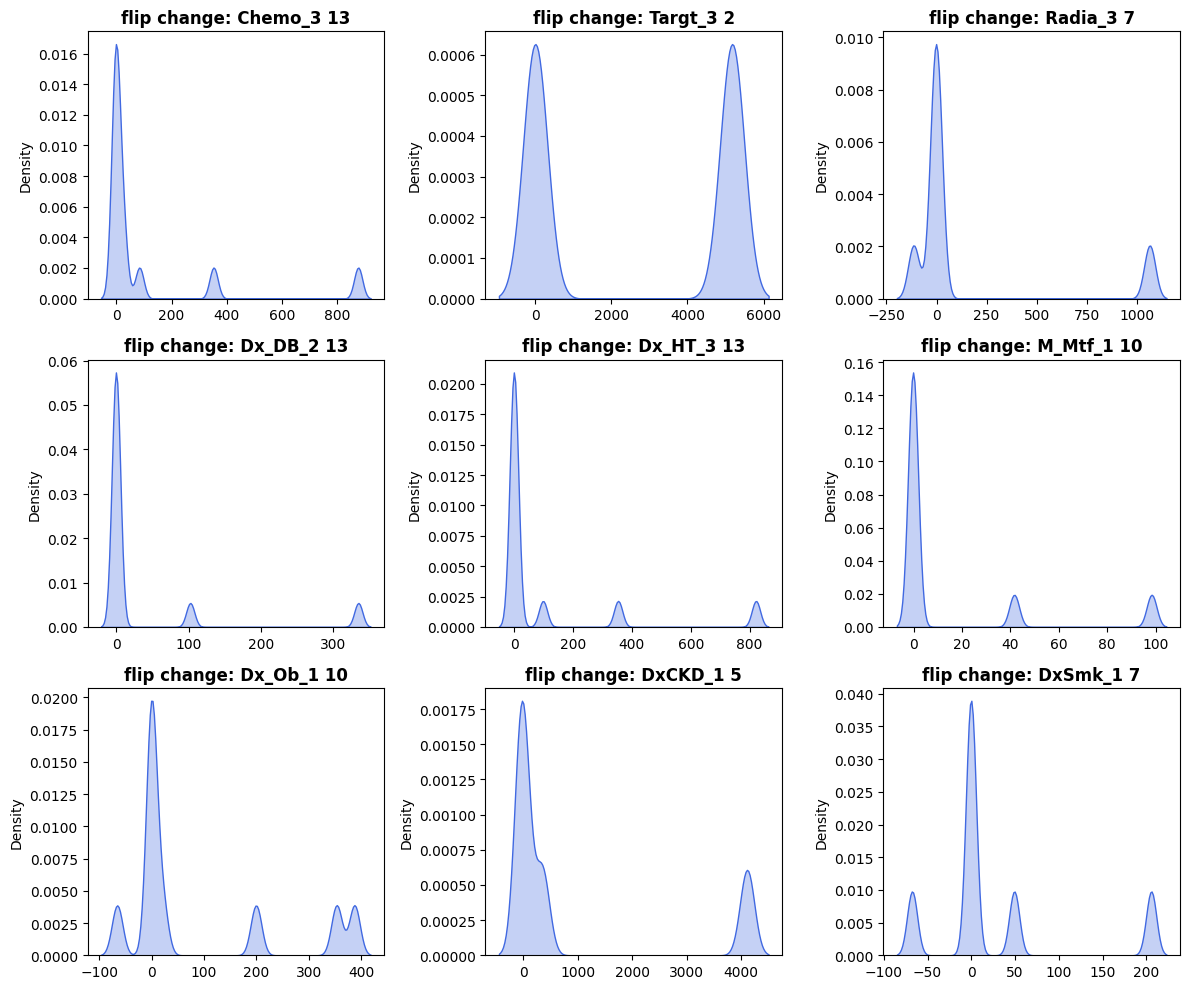

In [28]:

#slt_events = ['Chemo_1', 'Chemo_2', 'Chemo_3', 'Targt_1', 'Targt_2', 'Targt_3', 'Radia_1', 'Radia_2', 'Radia_3']
slt_events = ['Chemo_3', 'Targt_3', 'Radia_3', 'Dx_DB_2', 'Dx_HT_3', 'M_Mtf_1', 'Dx_Ob_1', 'DxCKD_1', 'DxSmk_1']



flip_analyzer.plot_relv_changes(path_info, slt_events)
flip_analyzer.plot_flip_changes(path_info, slt_events)